# Evaluation-set selection bias of the compute frontier (Figure 4)

Runs the `transfer` experiment of `scaling/dataset_sample_efficiency.py` (21 TabArena datasets,
$n \in \{1, 2, 3, 5, 8, 12, 16, 20\}$ selection datasets, 20 repetitions; Appendix A.4) or loads its cache from
`cache/selection_bias/`, and draws Figure 4. To recompute, delete the cache.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

from scaling import dataset_sample_efficiency as dse

sns.set_style("white")


# Data Loading


In [2]:
figure_path = Path.cwd() / "figures"
figure_path.mkdir(parents=True, exist_ok=True)
cache_path = Path.cwd() / "cache" / "selection_bias"

df = pd.read_csv("../data/nanotabpfn_model_tabiclv1_prior.csv", index_col=[0, 1])

FILTER_FLOPS_MAX = 1.00000000e+16 * 1.05
FILTER_FLOPS_MIN = 1.00000000e+11 * 0.95
df = df[(FILTER_FLOPS_MAX > df['total_flops_rounded']) & (df['total_flops_rounded'] > FILTER_FLOPS_MIN)]


# Metric colours


In [3]:
flops_column = 'total_flops_rounded'

LOSS_STYLES = {
    'real_data/nll':       {"color": "#d1121f", "linestyle": "-",  "linewidth": 4.5, "label": "NLL"},
    'real_data/roc_auc':   {"color": "#e07b00", "linestyle": "-",  "linewidth": 1.8, "label": "ROC AUC"},
    'val/val_loss':        {"color": "#2a78d6", "linestyle": "--", "linewidth": 5.0, "label": "val loss"},
    'val/small/val_loss':  {"color": "#1baf7a", "linestyle": "--", "linewidth": 3.0, "label": "val loss (small)"},
    'val/medium/val_loss': {"color": "#4a3aa7", "linestyle": "--", "linewidth": 1.4, "label": "val loss (medium)"},
}


# Selection bias of the in-sample frontier

For each repetition, size `n` and target dataset, the best run per FLOP level is picked on the mean over `n` of the
other 20 datasets. The **in-sample front** scores it on those `n` datasets, the **honest front** on the target; both
are pooled over the 21 targets, with the running best taken on the in-sample means only. Selection bias is in-sample
minus honest (reversed for NLL). It is compared with the residual of the law fitted to each study's own in-sample
front; the criterion is the smallest `n` whose median bias is below the median residual.

In [4]:
T_N_REPS = 20
T_N_TRAIN = [1, 2, 3, 5, 8, 12, 16, 20]
BASE_SEED = 0
METRICS = ["roc_auc", "nll"]
ERROR_THRESHOLD = {"roc_auc": 0.01, "nll": 0.02}   # median-MAE thresholds, in metric units
METRIC_LABEL = {"roc_auc": "ROC AUC", "nll": "NLL"}
sns.set_context("talk")

transfer_config = dse.ExperimentConfig.transfer(
    data_path="../data/nanotabpfn_model_tabiclv1_prior.csv",
    out_dir=str(cache_path),
    n_reps=T_N_REPS,
    n_train=tuple(T_N_TRAIN),
    base_seed=BASE_SEED,
    metrics=tuple(METRICS),
    error_threshold=ERROR_THRESHOLD,
    n_jobs=-1,
)

_t0 = time.time()
transfer = dse.run_cached(transfer_config, df=df)   # loads the cache if out_dir/config.json matches
print(f"cell wall time: {time.time() - _t0:.1f} s")
t_curves, t_errors, t_summary, t_refs = transfer["curves"], transfer["errors"], transfer["summary"], transfer["references"]
t_stab, t_stab_summary, t_threshold = transfer["stability"], transfer["stability_summary"], transfer["threshold"]
t_study, t_study_summary = transfer["per_study"], transfer["per_study_summary"]
print(len(transfer["splits"]), "(target, repetition) splits;", len(transfer["fits"]), "fits;", len(transfer["per_dataset_values"]), "per-dataset evaluations")
t_refs


Experiment finished in 447.1 s, saved to playground/cache/selection_bias
cell wall time: 447.1 s
420 (target, repetition) splits; 324 fits; 134400 per-dataset evaluations


,metric,law_resolution_mae,law_resolution_rmse,noise_floor_mae,noise_floor_rmse,winners_curse_mae,winners_curse_rmse,winners_curse_signed,winners_curse_optimism
0,roc_auc,0.004683,0.006479,0.007149,0.009432,0.007474,0.010032,0.007474,0.007474
1,nll,0.007796,0.010996,0.009859,0.011840,0.004905,0.006882,-0.004905,0.004905


## Figure 4: selection bias against n

Solid: pooled selection bias, median with 10-90 % band over repetitions. Dotted: median residual of the per-study law.

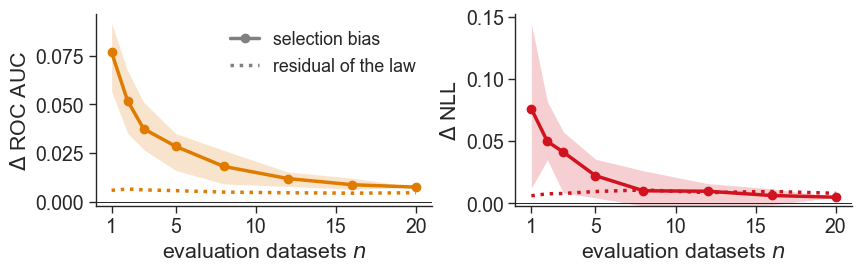

In [5]:
def t_series(metric, quantity, column="median"):
    sub = t_summary[(t_summary["metric"] == metric) & (t_summary["quantity"] == quantity)].sort_values("n_train")
    return sub["n_train"].to_numpy(), sub[column].to_numpy()


# Paper figure: linear n axis, one row, large text; legend inside the left panel (neutral colour, valid for both).
sns.set_style("ticks")
with sns.plotting_context("paper", font_scale=1.6):
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.6), layout="constrained")
    for ax, metric in zip(axes, METRICS):
        color = LOSS_STYLES[f"real_data/{metric}"]["color"]
        n, med = t_series(metric, "optimism_mean")
        _, lo = t_series(metric, "optimism_mean", "q10")
        _, hi = t_series(metric, "optimism_mean", "q90")
        ax.fill_between(n, lo, hi, color=color, alpha=0.2, linewidth=0)
        ax.plot(n, med, color=color, linewidth=2.5, marker="o", markersize=6)
        study = t_study_summary[t_study_summary["metric"] == metric]
        res = study[study["quantity"] == "residual_study"].sort_values("n_train")
        ax.plot(res["n_train"], res["median"], color=color, linewidth=2.5, linestyle=":")
        ax.axhline(0, color="black", linewidth=0.6)
        ax.set_xticks([1, 5, 10, 15, 20])
        ax.set_xlim(0, 21)
        ax.set_ylim(bottom=-0.002)
        ax.set_xlabel("evaluation datasets $n$")
        ax.set_ylabel(f"$\\Delta$ {METRIC_LABEL[metric]}")
    handles = [
        Line2D([], [], color="grey", linewidth=2.5, marker="o", markersize=6, label="selection bias"),
        Line2D([], [], color="grey", linewidth=2.5, linestyle=":", label="residual of the law"),
    ]
    axes[0].legend(handles=handles, loc="upper right", frameon=False, handlelength=1.6, fontsize="small")
    sns.despine(fig)
    fig.savefig(figure_path / "selection_bias.pdf")
    plt.show()
sns.set_style("white")


## In-sample vs honest fronts

Median in-sample front (hollow), median honest front (filled black) and the law fitted to the full-benchmark front (dashed).

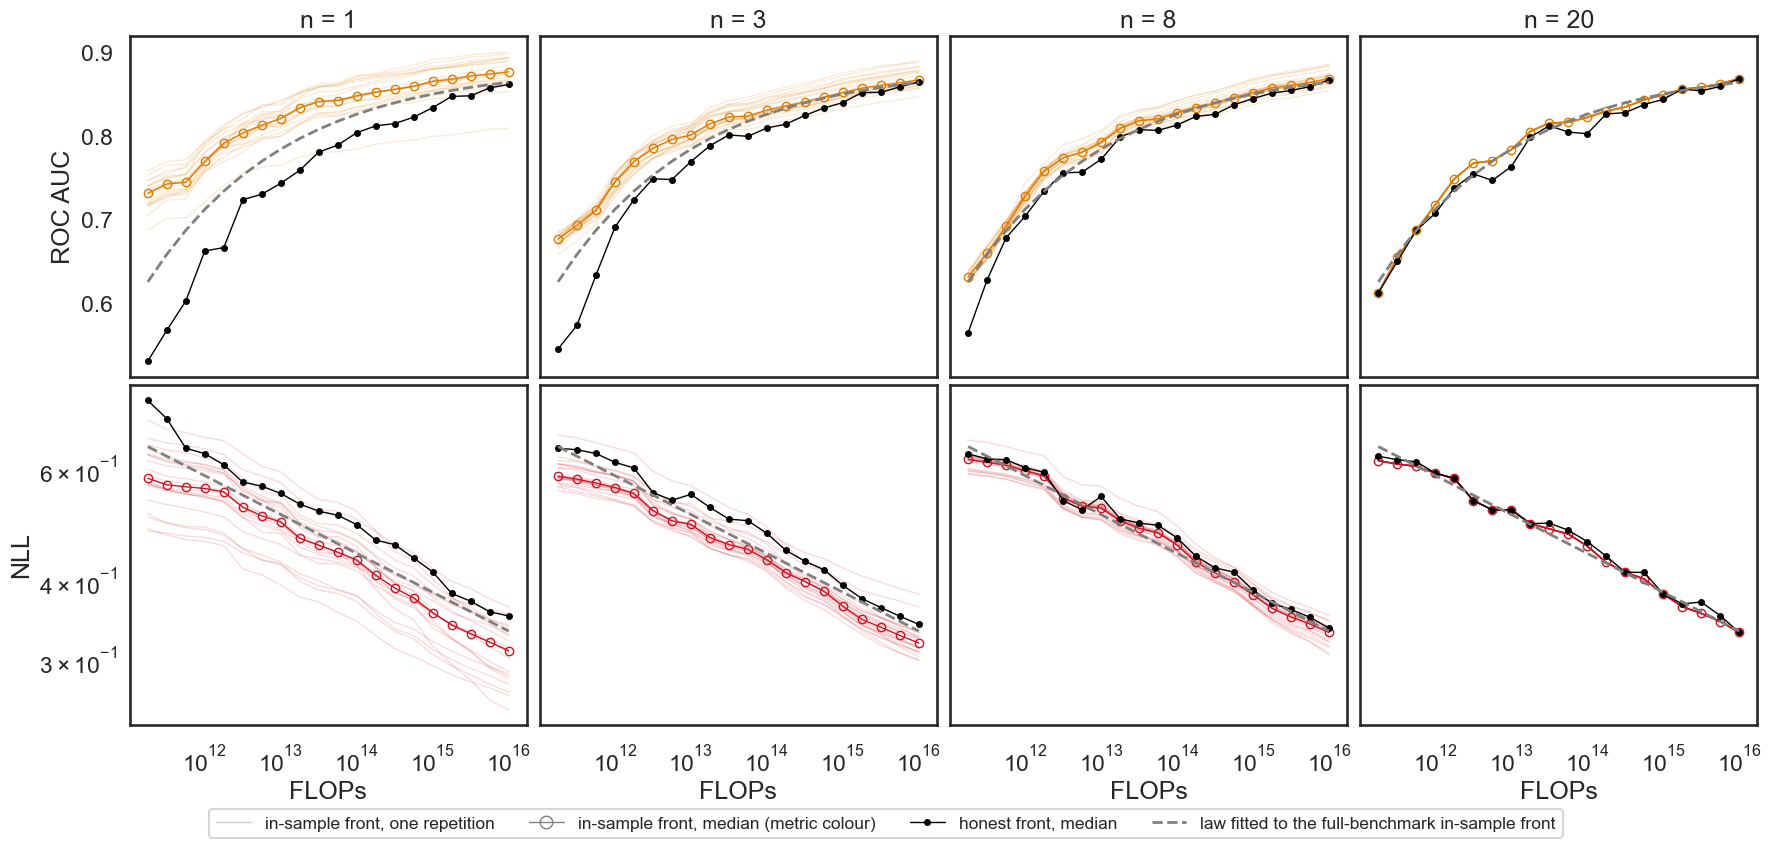

In [6]:
SHOW_T_N = [n for n in [1, 3, 8, 20] if n in T_N_TRAIN]
fig, axes = plt.subplots(len(METRICS), len(SHOW_T_N), figsize=(4.4 * len(SHOW_T_N), 4.2 * len(METRICS)),
                         layout="constrained", sharex=True, sharey="row", squeeze=False)
for r, metric in enumerate(METRICS):
    color = LOSS_STYLES[f"real_data/{metric}"]["color"]
    for c, n in enumerate(SHOW_T_N):
        ax = axes[r, c]
        sub = t_curves[(t_curves["metric"] == metric) & (t_curves["n_train"] == n)]
        for _, g in sub.groupby("rep"):
            ax.plot(g["flops"], g["insample"], color=color, alpha=0.15, linewidth=1)
        med = sub.groupby("flops")[["insample", "honest", "full_benchmark_law"]].median()
        ax.plot(med.index, med["insample"], color=color, linewidth=1, marker="o", markerfacecolor="none", markersize=6)
        ax.plot(med.index, med["honest"], color="black", linewidth=1, marker="o", markersize=4)
        ax.plot(med.index, med["full_benchmark_law"], color="grey", linestyle="--", linewidth=2)
        ax.set_xscale("log")
        if metric == "nll":
            ax.set_yscale("log")
        if r == 0:
            ax.set_title(f"n = {n}")
        if c == 0:
            ax.set_ylabel(METRIC_LABEL[metric])
        if r == len(METRICS) - 1:
            ax.set_xlabel("FLOPs")
handles = [
    Line2D([], [], color="grey", alpha=0.4, linewidth=1, label="in-sample front, one repetition"),
    Line2D([], [], color="grey", linewidth=1, marker="o", markerfacecolor="none", label="in-sample front, median (metric colour)"),
    Line2D([], [], color="black", linewidth=1, marker="o", markersize=4, label="honest front, median"),
    Line2D([], [], color="grey", linestyle="--", linewidth=2, label="law fitted to the full-benchmark in-sample front"),
]
fig.legend(handles=handles, loc="outside lower center", ncol=4, fontsize="x-small")
fig.savefig(figure_path / "selection_bias_fronts.pdf")
plt.show()
